In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
current_file = Path.cwd()

In [2]:
df = pd.read_csv(current_file / "Dataset" / "ushape.csv")

In [117]:
df.head()

,X,Y,CLASS
0,2.1200,-0.0462,1.0
1,0.8820,-0.0758,0.0
2,-0.0551,-0.0373,1.0
3,0.8300,-0.5390,1.0
4,2.1100,0.6620,1.0


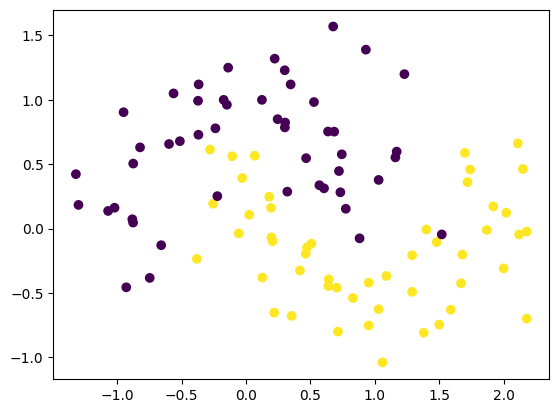

In [118]:
plt.scatter(df['X'],df['Y'],c=df['CLASS'])

In [119]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [120]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [121]:
model = Sequential()

model.add(Dense(2,activation='tanh',input_dim=2))
model.add(Dense(2,activation='tanh'))
model.add(Dense(2,activation='tanh'))
model.add(Dense(2,activation='tanh'))
model.add(Dense(1,activation='sigmoid'))

model.summary()

Model: "sequential_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_19 (Dense)            (None, 2)                 6         
                                                                 
 dense_20 (Dense)            (None, 2)                 6         
                                                                 
 dense_21 (Dense)            (None, 2)                 6         
                                                                 
 dense_22 (Dense)            (None, 2)                 6         
                                                                 
 dense_23 (Dense)            (None, 1)                 3         
                                                                 
Total params: 27
Trainable params: 27
Non-trainable params: 0
_________________________________________________________________


In [122]:
# Set parameters to 0
model.get_weights()

[array([[0.15201855, 0.73730874],
        [0.07251167, 0.824772  ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 1.1103934, -1.2235789],
        [-0.5541987, -1.1098396]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 0.1772747 ,  0.8077675 ],
        [-0.24643356,  1.0101999 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[ 0.13123   ,  0.40082932],
        [ 0.221529  , -0.06782126]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[-0.53052866],
        [ 0.27015686]], dtype=float32),
 array([0.], dtype=float32)]

In [123]:
initial_weights = model.get_weights()

In [ ]:
# initial_weights[0] = np.zeros(model.get_weights()[0].shape)
# initial_weights[1] = np.zeros(model.get_weights()[1].shape)
# initial_weights[2] = np.zeros(model.get_weights()[2].shape)
# initial_weights[3] = np.zeros(model.get_weights()[3].shape)

# initial_weights[0] = np.ones(model.get_weights()[0].shape)*0.5 
# initial_weights[1] = np.ones(model.get_weights()[1].shape)*0.5
# initial_weights[2] = np.ones(model.get_weights()[2].shape)*0.5
# initial_weights[3] = np.ones(model.get_weights()[3].shape)*0.5

initial_weights[0] = np.random.randn(model.get_weights()[0].shape[0], model.get_weights()[0].shape[1])*0.01 
initial_weights[1] = np.ones(model.get_weights()[1].shape)
initial_weights[2] = np.random.randn(model.get_weights()[2].shape[0], model.get_weights()[2].shape[1])*0.01 
initial_weights[3] = np.ones(model.get_weights()[3].shape)
initial_weights[4] = np.random.randn(model.get_weights()[4].shape[0], model.get_weights()[4].shape[1])*0.01 
initial_weights[5] = np.ones(model.get_weights()[5].shape)
initial_weights[6] = np.random.randn(model.get_weights()[6 ].shape[0], model.get_weights()[6].shape[1])*0.01 
initial_weights[7] = np.ones(model.get_weights()[7].shape)
initial_weights[8] = np.random.randn(model.get_weights()[8].shape[0], model.get_weights()[8].shape[1])*0.01 
initial_weights[9] = np.ones(model.get_weights()[9].shape)


In [125]:
model.set_weights(initial_weights)

In [126]:
model.get_weights()

[array([[-0.00171318, -0.01020853],
        [-0.01284127, -0.00785227]], dtype=float32),
 array([1., 1.], dtype=float32),
 array([[-0.0126468 ,  0.00793413],
        [-0.01134906,  0.01136193]], dtype=float32),
 array([1., 1.], dtype=float32),
 array([[-0.0047195 , -0.00867161],
        [ 0.0051029 ,  0.00324004]], dtype=float32),
 array([1., 1.], dtype=float32),
 array([[ 0.01681718,  0.00670111],
        [ 0.01905506, -0.00016424]], dtype=float32),
 array([1., 1.], dtype=float32),
 array([[-0.01194071],
        [-0.02506511]], dtype=float32),
 array([1.], dtype=float32)]

In [127]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [128]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100
3/3 [==============================] - 0s 53ms/step - loss: 0.8002 - accuracy: 0.5063 - val_loss: 0.8051 - val_accuracy: 0.5000
Epoch 2/100
3/3 [==============================] - 0s 12ms/step - loss: 0.7985 - accuracy: 0.5063 - val_loss: 0.8033 - val_accuracy: 0.5000
Epoch 3/100
3/3 [==============================] - 0s 12ms/step - loss: 0.7968 - accuracy: 0.5063 - val_loss: 0.8016 - val_accuracy: 0.5000
Epoch 4/100
3/3 [==============================] - 0s 12ms/step - loss: 0.7951 - accuracy: 0.5063 - val_loss: 0.7999 - val_accuracy: 0.5000
Epoch 5/100
3/3 [==============================] - 0s 12ms/step - loss: 0.7935 - accuracy: 0.5063 - val_loss: 0.7982 - val_accuracy: 0.5000
Epoch 6/100
3/3 [==============================] - 0s 12ms/step - loss: 0.7920 - accuracy: 0.5063 - val_loss: 0.7965 - val_accuracy: 0.5000
Epoch 7/100
3/3 [==============================] - 0s 12ms/step - loss: 0.7902 - accuracy: 0.5063 - val_loss: 0.7948 - val_accuracy: 0.5000
Epoch 8/100
3/3 [===

In [129]:
model.get_weights()

[array([[-0.35382578, -0.36472696],
        [ 0.32183325,  0.32883683]], dtype=float32),
 array([1.0041665, 0.9972799], dtype=float32),
 array([[0.273879  , 0.29330546],
        [0.27718833, 0.2988014 ]], dtype=float32),
 array([1.2463235, 1.244685 ], dtype=float32),
 array([[0.28660122, 0.28417882],
        [0.2956472 , 0.29532513]], dtype=float32),
 array([1.2804629, 1.2821872], dtype=float32),
 array([[0.28758213, 0.26736307],
        [0.28994474, 0.26063013]], dtype=float32),
 array([1.2612658, 1.250592 ], dtype=float32),
 array([[-0.23819071],
        [-0.2515439 ]], dtype=float32),
 array([0.7844638], dtype=float32)]

9600/9600 [==============================] - 9s 893us/step


<Axes: >

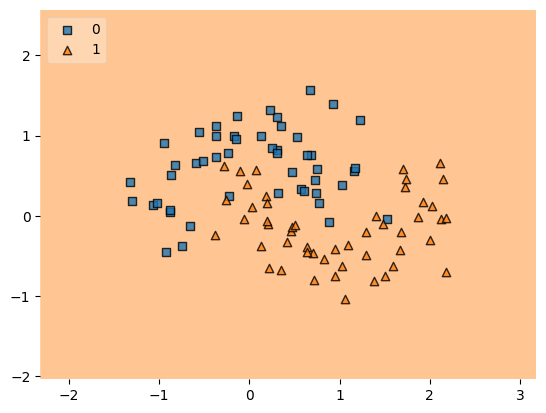

In [130]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X,y.astype('int'), clf=model, legend=2)